In [1]:
import kagglehub
import os
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. تحميل الداتا سيت من Kaggle
path = kagglehub.dataset_download("rahibvk/real-diabetes-lab-results-and-biomarkers-anti-pima")

# 2. قراءة ملف الـ CSV
file_path = os.path.join(path, 'custom_multi_year_diabetes_dataset.csv')
df = pd.read_csv(file_path)

# 3. معالجة وتحديد الـ Target والخصائص (Features)
df['Binary_Target'] = (df['Diabetes_Status'] > 0).astype(int)
df['Gender_Num'] = df['Gender'].map({'Male': 1, 'Female': 0})
feature_columns = ['Age', 'Gender_Num', 'BMI', 'Systolic_BP', 'Diastolic_BP', 'HbA1c_Level']

X = df[feature_columns].values
y = df['Binary_Target'].values

# 4. تقسيم البيانات وتطبيق الـ StandardScaler
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("تم قراءة وتجهيز البيانات بنجاح وجاهزة للتدريب!")

100%|██████████| 169k/169k [00:00<00:00, 17.7MB/s]

Extracting files...


تم قراءة وتجهيز البيانات بنجاح وجاهزة للتدريب!


Using Colab cache for faster access to the 'real-diabetes-lab-results-and-biomarkers-anti-pima' dataset.


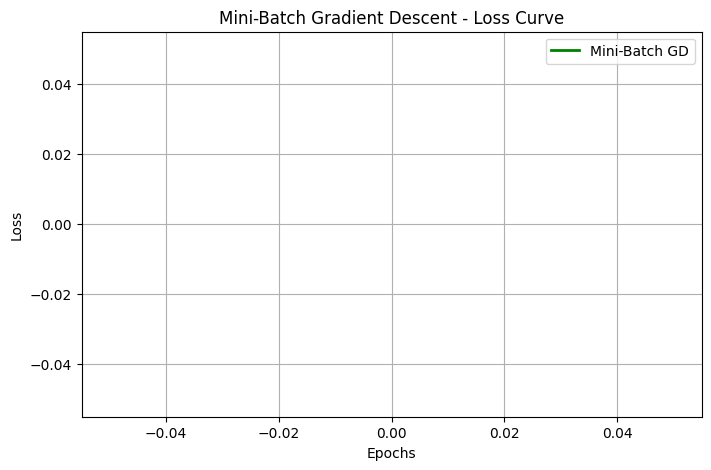

تم تدريب نموذج Mini-Batch GD بنجاح وعرض المنحنى الأخضر!


In [3]:
import kagglehub
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. تحميل الداتا وتجهيزها
path = kagglehub.dataset_download("rahibvk/real-diabetes-lab-results-and-biomarkers-anti-pima")
file_path = os.path.join(path, 'custom_multi_year_diabetes_dataset.csv')
df = pd.read_csv(file_path)

df['Binary_Target'] = (df['Diabetes_Status'] > 0).astype(int)
df['Gender_Num'] = df['Gender'].map({'Male': 1, 'Female': 0})
feature_columns = ['Age', 'Gender_Num', 'BMI', 'Systolic_BP', 'Diastolic_BP', 'HbA1c_Level']

X = df[feature_columns].values
y = df['Binary_Target'].values

# 2. التقسيم والتطبيع
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 3. الدوال الأساسية
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

def compute_loss(y_true, y_pred_proba):
    epsilon = 1e-15
    y_pred_proba = np.clip(y_pred_proba, epsilon, 1 - epsilon)
    m = len(y_true)
    return -(1 / m) * np.sum(y_true * np.log(y_pred_proba) + (1 - y_true) * np.log(1 - y_pred_proba))

# 4. كلاس Mini-Batch Gradient Descent
class MiniBatchGDLogisticRegression:
    def __init__(self, lr=0.05, epochs=30, batch_size=64):
        self.lr = lr
        self.epochs = epochs
        self.batch_size = batch_size
        self.loss_history = []

    def fit(self, X, y):
        m, n = X.shape
        self.w = np.zeros(n)
        self.b = 0.0
        self.loss_history = []

        for epoch in range(self.epochs):
            # خلط البيانات عشوائياً في كل دورة
            indices = np.random.permutation(m)
            X_shuffled = X[indices]
            y_shuffled = y[indices]

            # التحديث يتم على دفعات (Batches) بحجم batch_size
            for i in range(0, m, self.batch_size):
                X_batch = X_shuffled[i:i+self.batch_size]
                y_batch = y_shuffled[i:i+self.batch_size]
                current_batch_size = X_batch.shape[0]

                z = np.dot(X_batch, self.w) + self.b
                y_hat = sigmoid(z)

                dw = (1 / current_batch_size) * np.dot(X_batch.T, (y_hat - y_batch))
                db = (1 / current_batch_size) * np.sum(y_hat - y_batch)

                self.w -= self.lr * dw
                self.b -= self.lr * db

            # تسجيل الخسارة بعد نهاية كل Epoch كاملة
            y_pred_all = sigmoid(np.dot(X, self.w) + self.b)
            loss = compute_loss(y, y_pred_all)
            self.loss_history.append(loss)

# 5. التدريب ورسم المنحنى
model_minibatch = MiniBatchGDLogisticRegression(lr=0.05, epochs=30, batch_size=64)
model_minibatch.fit(X_train, y_train)

plt.figure(figsize=(8, 5))
plt.plot(model_minibatch.loss_history, label='Mini-Batch GD', color='green', linewidth=2)
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Mini-Batch Gradient Descent - Loss Curve')
plt.legend()
plt.grid(True)
plt.show()

print("تم تدريب نموذج Mini-Batch GD بنجاح وعرض المنحنى الأخضر!")